# 3.4 Practical A: AlphaFold Confidence, Validation & Clinical Pathogenicity

In [**3.3 AlphaFold, Clinical Mutations & Molecular Dynamics**](05-alphafold-and-clinical-mutations.md), we introduced the real-world structural biology pipeline that pairs **AI structure prediction (AlphaFold & AlphaMissense)** with **experimental structures** and **physics-based MD**.

In this live Python practical, you will:
1. Explore the full-length **human MYD88** AlphaFold prediction (`AF-Q99836-F1`) in 3D, coloured by **pLDDT confidence**, with the Waldenström Macroglobulinemia hotspot **L265P (UniProt L252P)** pinpointed.
2. Plot MYD88's **per-residue pLDDT** and **296 × 296 PAE domain packing matrix** to separate rigid folded domains from flexible linkers.
3. Superpose AlphaFold MYD88 against **two real experimental structures** (`7L6W` active-like assembly vs `4EO7` monomeric crystal) to discover the **20.8 Å BB-loop conformational switch**.
4. Query real **AlphaMissense** clinical pathogenicity data across **MYD88**, **Haemoglobin β (Sickle-Cell Disease E6V — an AI blind spot!)**, and **Proinsulin (Akita Neonatal Diabetes C96Y)**.

Click **⚡ Activate Live Editable Python Cells** above to edit and run every cell live in your browser!

## Step 1: Import Python Libraries & Locate Our AlphaFold Dataset

All structures, PAE matrices, and AlphaMissense CSV tables in `data/alphafold/` come directly from the **EMBL-EBI AlphaFold Protein Structure Database (v6, CC-BY-4.0)** and the **RCSB Protein Data Bank** (`4EO7`, `7L6W`), pre-bundled so every cell runs offline in seconds.

In [1]:
import os
import sys
import warnings

warnings.filterwarnings("ignore")

# Locate the Molecular Dynamics workspace folder (works in live containers and local checkouts)
for candidate in ("/home/jovyan/work/MD", "MD", "tutorials/MD", "../../tutorials/MD"):
    if os.path.isdir(candidate):
        os.chdir(candidate)
        break

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
from md_helpers import (
    load_alphamissense,
    load_pae,
    load_plddt,
    view_structure,
    view_superposition,
)

AF_DIR = "data/alphafold"
myd88_full_pdb = f"{AF_DIR}/AF-Q99836-F1-model_v6.pdb"
myd88_pae_json = f"{AF_DIR}/AF-Q99836-F1-pae_v6.json"
myd88_am_csv   = f"{AF_DIR}/AF-Q99836-F1-am.csv"
myd88_tir_af   = f"{AF_DIR}/myd88_tir_AF_wt.pdb"
myd88_tir_4eo7 = f"{AF_DIR}/myd88_tir_4EO7_xray.pdb"
myd88_tir_7l6w = f"{AF_DIR}/myd88_tir_7L6W_assembly.pdb"

hbb_af_pdb     = f"{AF_DIR}/AF-P68871-F1-model_v6.pdb"
hbb_am_csv     = f"{AF_DIR}/AF-P68871-F1-am.csv"

ins_af_pdb     = f"{AF_DIR}/AF-P01308-F1-model_v6.pdb"
ins_am_csv     = f"{AF_DIR}/AF-P01308-F1-am.csv"

print("Working directory:", os.getcwd())
print("Bundled AlphaFold & PDB files:", sorted(os.listdir(AF_DIR)))

Working directory: /home/antigravity/SiFTW/interactivetutorials/tutorials/MD
Bundled AlphaFold & PDB files: ['AF-P01308-F1-am.csv', 'AF-P01308-F1-model_v6.pdb', 'AF-P01308-F1-pae_v6.json', 'AF-P68871-F1-am.csv', 'AF-P68871-F1-model_v6.pdb', 'AF-Q99836-F1-am.csv', 'AF-Q99836-F1-model_v6.pdb', 'AF-Q99836-F1-pae_v6.json', 'myd88_tir_4EO7_xray.pdb', 'myd88_tir_7L6W_assembly.pdb', 'myd88_tir_AF_L252P.pdb', 'myd88_tir_AF_wt.pdb', 'myd88_tir_wt_50ps.dcd', 'myd88_tir_wt_md.pdb']


## Step 2: Explore Full-Length Human MYD88 Coloured by AlphaFold pLDDT

AlphaFold stores each residue's **pLDDT confidence score (0–100)** directly in the PDB file's **B-factor column**.

Rotate the 3D model below and notice:
- Two compact, **blue** folded domains: the **Death Domain (aa 21–109)** and the **TIR Domain (aa 156–296)**.
- A **yellow/orange** flexible **N-terminal tail (aa 1–20)** and **Intermediary Linker (aa 110–155)** connecting them.
- The magenta spheres highlight **Leu252** — which corresponds to **clinical *MYD88* L265P** (+13 isoform offset) buried inside the TIR domain's central $\beta$-sheet!

In [2]:
view_structure(
    myd88_full_pdb,
    style="cartoon",
    color="plddt",
    highlight_residues=[252],
    highlight_labels={252: "L252 (clinical L265P)"},
    title="Human MYD88 (AF-Q99836-F1) — Coloured by AlphaFold pLDDT",
    height=460,
)

## Step 3: Quantify Confidence — Per-Residue pLDDT & the 296 × 296 PAE Matrix

Looking at a single static 3D model can fool you into thinking the **Death Domain** and **TIR Domain** are locked at a fixed distance from each other. The **Predicted Aligned Error (PAE)** matrix reveals the truth:
- **Dark green squares along the diagonal:** AlphaFold is highly confident about atom distances *within* the Death Domain and *within* the TIR Domain.
- **Pale off-diagonal rectangles:** PAE > 20 Å between the two domains — telling us they move independently on a flexible hinge!

Full-length MYD88 (UniProt Q99836): 296 residues
Position 252 = LEU252 (pLDDT = 88.1), sequence motif 248–257: HQKRLIPIKY
  N-terminal tail              (  1– 20): mean pLDDT = 45.2
  Death Domain (DD)            ( 21–109): mean pLDDT = 87.4
  Intermediary Linker (ID)     (110–155): mean pLDDT = 70.4
  TIR Domain (contains L252)   (156–296): mean pLDDT = 84.6


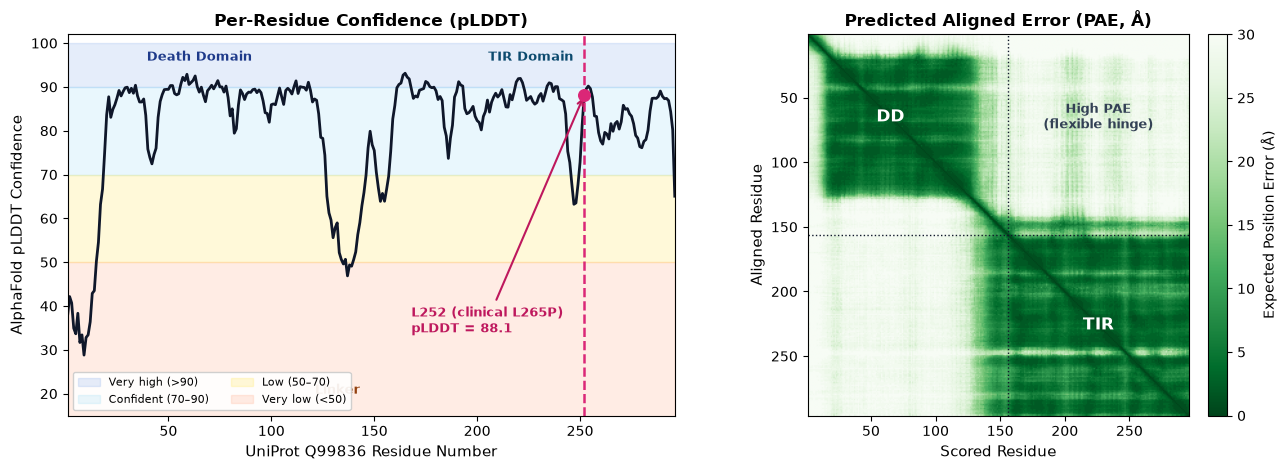

In [3]:
resids, resnames, plddt = load_plddt(myd88_full_pdb)
pae = load_pae(myd88_pae_json)

# Verify exact residue identity at position 252 (clinical L265P)
idx_252 = int(np.where(resids == 252)[0][0])
motif = "".join(
    {"ALA":"A","CYS":"C","ASP":"D","GLU":"E","PHE":"F","GLY":"G","HIS":"H",
     "ILE":"I","LYS":"K","LEU":"L","MET":"M","ASN":"N","PRO":"P","GLN":"Q",
     "ARG":"R","SER":"S","THR":"T","VAL":"V","TRP":"W","TYR":"Y"}[resnames[i]]
    for i in range(idx_252 - 4, idx_252 + 6)
)
print(f"Full-length MYD88 (UniProt Q99836): {len(resids)} residues")
print(f"Position 252 = {resnames[idx_252]}252 (pLDDT = {plddt[idx_252]:.1f}), sequence motif 248–257: {motif}")
for name, lo, hi in [
    ("N-terminal tail", 1, 20),
    ("Death Domain (DD)", 21, 109),
    ("Intermediary Linker (ID)", 110, 155),
    ("TIR Domain (contains L252)", 156, 296),
]:
    mask = (resids >= lo) & (resids <= hi)
    print(f"  {name:<28s} ({lo:3d}–{hi:3d}): mean pLDDT = {plddt[mask].mean():.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})

# Left panel: pLDDT profile
ax1.axhspan(90, 100, color="#0053d6", alpha=0.10, label="Very high (>90)")
ax1.axhspan(70, 90,  color="#65cbf3", alpha=0.14, label="Confident (70–90)")
ax1.axhspan(50, 70,  color="#ffdb13", alpha=0.16, label="Low (50–70)")
ax1.axhspan(0,  50,  color="#ff7d45", alpha=0.14, label="Very low (<50)")
ax1.plot(resids, plddt, color="#0f172a", linewidth=2)
ax1.axvline(252, color="#db2777", linestyle="--", linewidth=1.8)
ax1.scatter([252], [plddt[idx_252]], color="#db2777", s=70, zorder=5)
ax1.annotate(
    f"L252 (clinical L265P)\npLDDT = {plddt[idx_252]:.1f}",
    xy=(252, plddt[idx_252]),
    xytext=(168, 34),
    fontsize=9.5,
    fontweight="bold",
    color="#be185d",
    arrowprops=dict(arrowstyle="->", color="#be185d", lw=1.5),
)
ax1.text(65, 96, "Death Domain", ha="center", fontsize=9.5, fontweight="bold", color="#1e3a8a")
ax1.text(132, 20, "Linker", ha="center", fontsize=9, fontweight="bold", color="#92400e")
ax1.text(226, 96, "TIR Domain", ha="center", fontsize=9.5, fontweight="bold", color="#0c4a6e")
ax1.set_xlim(1, 296)
ax1.set_ylim(15, 102)
ax1.set_xlabel("UniProt Q99836 Residue Number", fontsize=11)
ax1.set_ylabel("AlphaFold pLDDT Confidence", fontsize=11)
ax1.set_title("Per-Residue Confidence (pLDDT)", fontsize=12, fontweight="bold")
ax1.legend(loc="lower left", fontsize=8, framealpha=0.92, ncol=2)

# Right panel: PAE heatmap
im = ax2.imshow(pae, cmap="Greens_r", vmin=0, vmax=30, origin="upper", extent=[1, 296, 296, 1])
ax2.axhline(156, color="#0f172a", linestyle=":", linewidth=1)
ax2.axvline(156, color="#0f172a", linestyle=":", linewidth=1)
ax2.text(65, 65, "DD", ha="center", va="center", color="white", fontsize=12, fontweight="bold")
ax2.text(226, 226, "TIR", ha="center", va="center", color="white", fontsize=12, fontweight="bold")
ax2.text(226, 65, "High PAE\n(flexible hinge)", ha="center", va="center", color="#334155", fontsize=9, fontweight="bold")
ax2.set_xlabel("Scored Residue", fontsize=11)
ax2.set_ylabel("Aligned Residue", fontsize=11)
ax2.set_title("Predicted Aligned Error (PAE, Å)", fontsize=12, fontweight="bold")
cbar = plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label("Expected Position Error (Å)", fontsize=10)

plt.tight_layout()
plt.show()

## Step 4: Validate AlphaFold vs. Experimental Structures (Discovering the BB-Loop Switch!)

How accurate is AlphaFold on MYD88's TIR domain? Let's superpose `myd88_tir_AF_wt.pdb` onto **two real experimental structures** from the Protein Data Bank:
1. **`7L6W`** — Serial Femtosecond Crystallography (SFX) structure of the **higher-order active-like MYD88 TIR assembly** *(Clabbers et al., Nature Communications, 2021)*.
2. **`4EO7`** — Monomeric X-ray crystal structure of the **isolated MYD88 TIR domain**.

Watch what happens when you compare both superpositions!

In [4]:
view_superposition(
    myd88_tir_af,
    myd88_tir_7l6w,
    ref_label="AlphaFold MYD88 TIR (AF-Q99836)",
    mobile_label="Experimental Assembly (PDB 7L6W)",
    ref_color="#2563eb",
    mobile_color="#16a34a",
    highlight_residues=[252],
    highlight_labels={252: "L252 (clinical L265P)"},
    title="AlphaFold MYD88 TIR vs Experimental Higher-Order Assembly (7L6W)",
    height=430,
)

**`0.70 Å` Cα RMSD across 135 residues** — AlphaFold reproduces the experimental assembly monomer to sub-ångström atomic precision!

Now compare that **exact same** AlphaFold model against the **monomeric X-ray structure (`4EO7`)** — and plot the **per-residue Cα distance** between the two structures!

In [5]:
# Align on the core excluding the BB-loop (195-208) so the loop swing stands out unmistakably
core_align_res = [r for r in range(159, 294) if not (195 <= r <= 208)]

view_superposition(
    myd88_tir_af,
    myd88_tir_4eo7,
    ref_label="AlphaFold MYD88 TIR (assembly-like state)",
    mobile_label="Experimental Monomer (PDB 4EO7)",
    ref_color="#2563eb",
    mobile_color="#ea580c",
    align_resids=core_align_res,
    highlight_residues=[252, 201],
    highlight_labels={252: "L252 (L265P)", 201: "BB-loop switch"},
    title="AlphaFold MYD88 TIR vs Monomeric Crystal (4EO7) — Spot the Swinging BB-Loop!",
    height=430,
)

AlphaFold vs 7L6W (assembly) — mean Cα diff: 0.56 Å (max: 2.58 Å)
AlphaFold vs 4EO7 (monomer)  — core mean:    1.43 Å | BB-loop max swing: 23.73 Å!


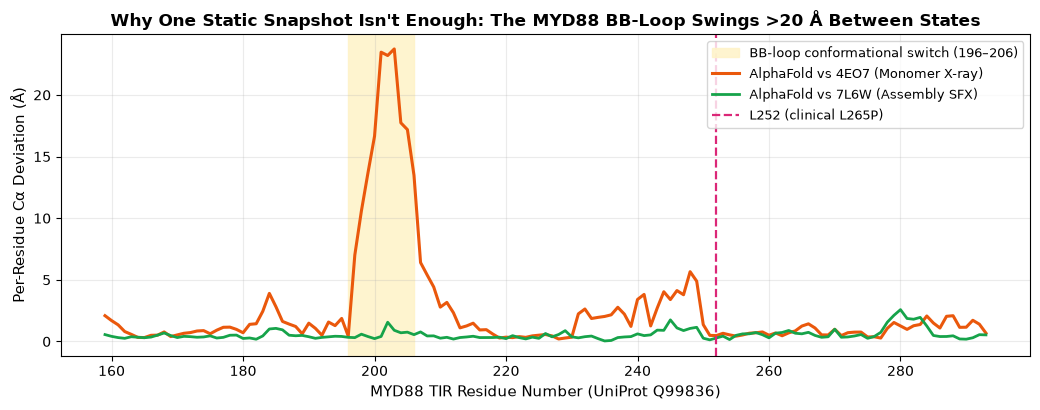

In [6]:
# Quantify per-residue Cα differences between AlphaFold and both experimental structures
from md_helpers import _kabsch_align

u_af   = mda.Universe(myd88_tir_af)
u_7l6w = mda.Universe(myd88_tir_7l6w)
u_4eo7 = mda.Universe(myd88_tir_4eo7)

def per_res_ca_diff(u_ref, u_mob, exclude_fit=()):
    ref_ca = {int(a.resid): a.position.copy() for a in u_ref.select_atoms("protein and name CA")}
    mob_ca = {int(a.resid): a.position.copy() for a in u_mob.select_atoms("protein and name CA")}
    common = sorted(r for r in (set(ref_ca) & set(mob_ca)) if 159 <= r <= 293)
    fit_r = [r for r in common if r not in exclude_fit]
    rot, mc, tc = _kabsch_align(
        np.asarray([mob_ca[r] for r in fit_r]),
        np.asarray([ref_ca[r] for r in fit_r]),
    )
    diffs = np.array([
        np.linalg.norm(((mob_ca[r] - mc) @ rot.T + tc) - ref_ca[r])
        for r in common
    ])
    return np.array(common), diffs

r_7l6w, d_7l6w = per_res_ca_diff(u_af, u_7l6w)
r_4eo7, d_4eo7 = per_res_ca_diff(u_af, u_4eo7, exclude_fit=set(range(195, 209)))

bb_mask = (r_4eo7 >= 196) & (r_4eo7 <= 206)
print(f"AlphaFold vs 7L6W (assembly) — mean Cα diff: {d_7l6w.mean():.2f} Å (max: {d_7l6w.max():.2f} Å)")
print(f"AlphaFold vs 4EO7 (monomer)  — core mean:    {d_4eo7[~bb_mask].mean():.2f} Å | BB-loop max swing: {d_4eo7[bb_mask].max():.2f} Å!")

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.axvspan(196, 206, color="#fef3c7", alpha=0.85, label="BB-loop conformational switch (196–206)")
ax.plot(r_4eo7, d_4eo7, color="#ea580c", linewidth=2.2, label="AlphaFold vs 4EO7 (Monomer X-ray)")
ax.plot(r_7l6w, d_7l6w, color="#16a34a", linewidth=2.0, label="AlphaFold vs 7L6W (Assembly SFX)")
ax.axvline(252, color="#db2777", linestyle="--", linewidth=1.6, label="L252 (clinical L265P)")
ax.set_xlabel("MYD88 TIR Residue Number (UniProt Q99836)", fontsize=11)
ax.set_ylabel("Per-Residue Cα Deviation (Å)", fontsize=11)
ax.set_title("Why One Static Snapshot Isn't Enough: The MYD88 BB-Loop Swings >20 Å Between States", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 5: Clinical Variant Pathogenicity Across MYD88 (Real AlphaMissense Data)

Now let's load the real **AlphaMissense** substitution table for human MYD88 (`AF-Q99836-F1-am.csv`, containing all **5,624** possible single amino acid mutations) and inspect:
1. Where MYD88 is structurally **intolerant** vs. **tolerant** to missense mutations.
2. How real patient mutations from **Waldenström Macroglobulinemia**, **DLBCL**, and **primary immunodeficiency** score!

*(Try editing `QUERY_VARIANTS` below to inspect any mutation you like — e.g. `"L252A"`, `"L252W"`, `"P254A"`, or `"E183A"`!)*

UniProt Var    Score  Class    Clinical / Biophysical Context
----------------------------------------------------------------------------------
L252P         0.9974  LPath    Clinical L265P — Waldenström / DLBCL (98% WM)
R196C         0.9826  LPath    Clinical R196C — BB-loop primary immunodeficiency
M219T         0.9777  LPath    Clinical M232T — DLBCL (contacts L252!)
S230N         0.7716  LPath    Clinical S243N — DLBCL gain-of-function
S206C         0.4538  Amb      Clinical S219C — DLBCL
L252I         0.4348  Amb      Conservative L252I — hydrophobic control
P125A         NOT FOUND (check wild-type amino acid at that position!)


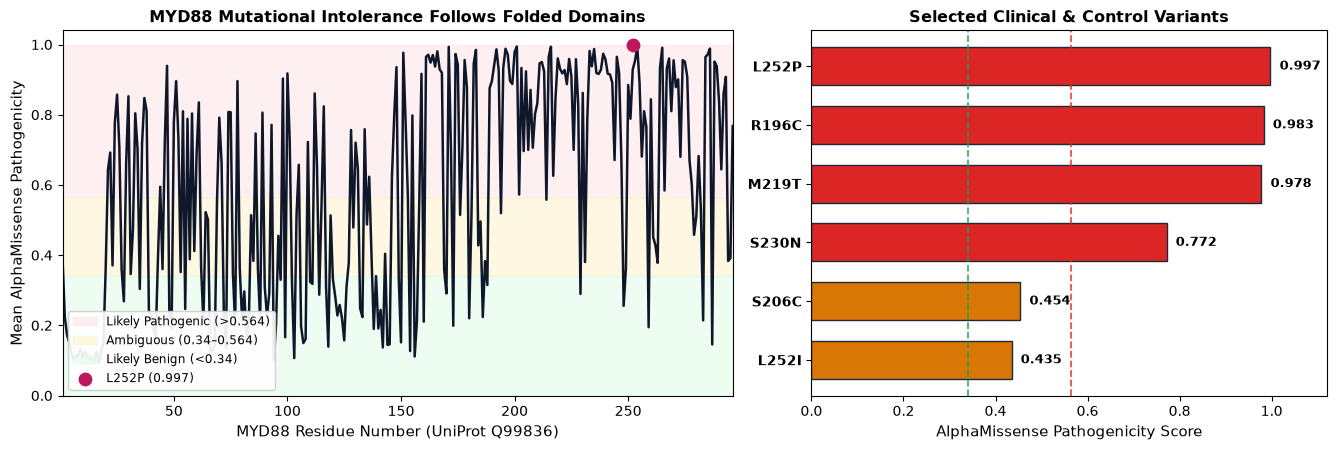

In [7]:
myd88_am, myd88_mean_am = load_alphamissense(myd88_am_csv)

# Edit or add any UniProt Q99836 variant below!
QUERY_VARIANTS = [
    ("L252P", "Clinical L265P — Waldenström / DLBCL (98% WM)"),
    ("R196C", "Clinical R196C — BB-loop primary immunodeficiency"),
    ("M219T", "Clinical M232T — DLBCL (contacts L252!)"),
    ("S230N", "Clinical S243N — DLBCL gain-of-function"),
    ("S206C", "Clinical S219C — DLBCL"),
    ("L252I", "Conservative L252I — hydrophobic control"),
    ("P125A", "Linker P125A — disordered linker control"),
]

print(f"{'UniProt Var':<12} {'Score':>7}  {'Class':<7}  Clinical / Biophysical Context")
print("-" * 82)
scores_plot, labels_plot, colors_plot = [], [], []
for var, desc in QUERY_VARIANTS:
    if var in myd88_am:
        sc, cls = myd88_am[var]
        print(f"{var:<12} {sc:7.4f}  {cls:<7}  {desc}")
        scores_plot.append(sc)
        labels_plot.append(f"{var}\n({desc.split('—')[0].strip()})")
        colors_plot.append("#dc2626" if cls == "LPath" else "#d97706" if cls == "Amb" else "#16a34a")
    else:
        print(f"{var:<12}  NOT FOUND (check wild-type amino acid at that position!)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

# Left: mean pathogenicity across full MYD88 sequence
am_res = np.array(sorted(myd88_mean_am.keys()))
am_vals = np.array([myd88_mean_am[r] for r in am_res])
ax1.axhspan(0.564, 1.0, color="#fee2e2", alpha=0.5, label="Likely Pathogenic (>0.564)")
ax1.axhspan(0.34, 0.564, color="#fef3c7", alpha=0.5, label="Ambiguous (0.34–0.564)")
ax1.axhspan(0.0, 0.34, color="#dcfce7", alpha=0.5, label="Likely Benign (<0.34)")
ax1.plot(am_res, am_vals, color="#0f172a", linewidth=1.8)
ax1.scatter([252], [myd88_am["L252P"][0]], color="#be185d", s=80, zorder=6, label="L252P (0.997)")
ax1.set_xlim(1, 296)
ax1.set_ylim(0, 1.04)
ax1.set_xlabel("MYD88 Residue Number (UniProt Q99836)", fontsize=11)
ax1.set_ylabel("Mean AlphaMissense Pathogenicity", fontsize=11)
ax1.set_title("MYD88 Mutational Intolerance Follows Folded Domains", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower left", fontsize=8.5, framealpha=0.92)

# Right: bar chart of selected variants
y_pos = np.arange(len(scores_plot))
ax2.barh(y_pos, scores_plot, color=colors_plot, edgecolor="#1e293b", height=0.65)
ax2.axvline(0.564, color="#dc2626", linestyle="--", linewidth=1.3, alpha=0.8)
ax2.axvline(0.34,  color="#16a34a", linestyle="--", linewidth=1.3, alpha=0.8)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([v for v, _ in QUERY_VARIANTS if v in myd88_am], fontsize=10, fontweight="bold")
ax2.invert_yaxis()
ax2.set_xlim(0, 1.12)
ax2.set_xlabel("AlphaMissense Pathogenicity Score", fontsize=11)
ax2.set_title("Selected Clinical & Control Variants", fontsize=11.5, fontweight="bold")
for i, sc in enumerate(scores_plot):
    ax2.text(sc + 0.02, i, f"{sc:.3f}", va="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()

## Step 6: The AI Blind Spot — MYD88 L265P vs. Sickle-Cell Disease (HbS E6V) vs. Akita Diabetes (Proinsulin C96Y)

Should a clinician ever trust an AI pathogenicity score **blindly** without checking the 3D structural and physiological mechanism? **No!**

Let's compare three iconic clinical missense mutations using their real EMBL-EBI AlphaMissense scores and AlphaFold 3D structures:
1. ***MYD88* L265P (`L252P`)** — Buried hydrophobic core disruption → gain-of-function oligomerisation
2. ***HBB* E6V (`E7V`, Sickle-Cell Disease)** — Solvent-exposed surface hydrophobic patch → **quaternary deoxy-Hb polymerisation**
3. ***INS* C96Y (Akita Neonatal Diabetes)** — Breaks the covalent **Cys31–Cys96 (`2.09 Å`)** inter-chain disulphide bridge → ER misfolding & $\beta$-cell death

In [8]:
hbb_am, _ = load_alphamissense(hbb_am_csv)
ins_am, _ = load_alphamissense(ins_am_csv)

cases = [
    ("MYD88 L265P (Waldenström)", "Q99836", "L252P", myd88_am["L252P"], "Buried βD-strand core → allosteric BB-loop switch"),
    ("HBB E6V (Sickle-Cell HbS)", "P68871", "E7V",   hbb_am["E7V"],     "Solvent-exposed surface → deoxy-Hb fibre polymerisation"),
    ("INS C96Y (Akita Diabetes)", "P01308", "C96Y",  ins_am["C96Y"],    "Breaks Cys31–Cys96 disulphide (2.09 Å) → misfolding"),
]

print(f"{'Clinical Mutation':<28} {'UniProt':<8} {'Var':<6} {'AM Score':>8} {'Class':<6}  Mechanism")
print("-" * 108)
for name, acc, var, (sc, cls), mech in cases:
    print(f"{name:<28} {acc:<8} {var:<6} {sc:8.4f} {cls:<6}  {mech}")

# Measure exact Cys31-Cys96 SG-SG distance in AlphaFold Proinsulin
u_ins = mda.Universe(ins_af_pdb)
sg31 = u_ins.select_atoms("resid 31 and name SG").positions[0]
sg96 = u_ins.select_atoms("resid 96 and name SG").positions[0]
print(f"\nVerified Proinsulin Cys31–Cys96 S–S distance in AF-P01308-F1: {np.linalg.norm(sg31 - sg96):.2f} Å (covalent disulphide!)")

Clinical Mutation            UniProt  Var    AM Score Class   Mechanism
------------------------------------------------------------------------------------------------------------
MYD88 L265P (Waldenström)    Q99836   L252P    0.9974 LPath   Buried βD-strand core → allosteric BB-loop switch
HBB E6V (Sickle-Cell HbS)    P68871   E7V      0.2229 LBen    Solvent-exposed surface → deoxy-Hb fibre polymerisation
INS C96Y (Akita Diabetes)    P01308   C96Y     0.9976 LPath   Breaks Cys31–Cys96 disulphide (2.09 Å) → misfolding

Verified Proinsulin Cys31–Cys96 S–S distance in AF-P01308-F1: 2.09 Å (covalent disulphide!)


Look at **Haemoglobin β (`AF-P68871-F1`)** in 3D below — notice that **Glu7 (clinical E6V)** sticks straight out into water on the outer surface of the monomer (very high pLDDT `96.6`, zero buried steric clash!). Because AlphaMissense evaluates monomeric structure & sequence conservation, it classifies **Sickle-Cell Disease** as **`0.223` ("Likely Benign")** — a textbook reminder of why structural biophysics and protein–protein dynamics are irreplaceable in clinical genomics!

In [9]:
view_structure(
    hbb_af_pdb,
    style="cartoon",
    color="plddt",
    highlight_residues=[7],
    highlight_labels={7: "E7 (clinical Sickle-Cell E6V)"},
    title="Haemoglobin β Monomer (AF-P68871-F1) — Sickle-Cell E6V Sits Exposed on the Surface!",
    height=420,
)

And inspect **Proinsulin (`AF-P01308-F1`)** below — notice how **Cys31** and **Cys96** (magenta) sit locked together at **`2.09 Å`** in an essential inter-chain disulphide bridge, while the unprocessed **C-peptide** and tails appear yellow/orange (low pLDDT)!

In [10]:
view_structure(
    ins_af_pdb,
    style="cartoon",
    color="plddt",
    highlight_residues=[31, 96],
    highlight_labels={31: "Cys31 (B-chain)", 96: "Cys96 (Akita C96Y)"},
    title="Human Proinsulin (AF-P01308-F1) — Essential Cys31–Cys96 Disulphide Bridge (2.09 Å)",
    height=420,
)

---

### Class Discussion & Next Step

1. Why did **MYD88**'s PAE plot show two separate dark-green squares — and why does that justify excising the **TIR domain (157–296)** for MD simulations?
2. AlphaFold matched **`7L6W`** to **`0.70 Å`**, yet differed from **`4EO7`** by **`20.8 Å`** in the **BB-loop**. What does this teach us about treating an AlphaFold structure as "the" structure of a protein?
3. Why did AlphaMissense score **MYD88 L265P (`0.997`)** and **Proinsulin C96Y (`0.998`)** as Likely Pathogenic, while scoring **Sickle-Cell Haemoglobin E6V (`0.223`)** as Likely Benign?

Ready to bring **MYD88 L265P** to life with Newton's laws of motion? Continue to [**3.5 Practical B: Simulating MYD88 L265P & Clinical Mutations in OpenMM**](07-myd88-l265p-md-simulation.ipynb)!